# Perform Career Analysis of a Renowned Football Player

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
results = pd.read_csv("results.csv")
goalscorers = pd.read_csv("goalscorers.csv")
former_names = pd.read_csv("former_names.csv")
shootouts = pd.read_csv("shootouts.csv")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
print("Results:", results.shape)
print("Goalscorers:", goalscorers.shape)
print("Former Names:", former_names.shape)
print("Shootouts:", shootouts.shape)

Results: (49547, 9)
Goalscorers: (47914, 8)
Former Names: (683, 5)
Shootouts: (683, 5)


In [ ]:
print("Results Dataset")
display(results.head())

print("Goalscorers Dataset")
display(goalscorers.head())

print("Former Names Dataset")
display(former_names.head())

print("Shootouts Dataset")
display(shootouts.head())

Results Dataset


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
0,1872-11-30,Scotland,England,0,0,Friendly,Glasgow,Scotland,False
1,1873-03-08,England,Scotland,4,2,Friendly,London,England,False
2,1874-03-07,Scotland,England,2,1,Friendly,Glasgow,Scotland,False
3,1875-03-06,England,Scotland,2,2,Friendly,London,England,False
4,1876-03-04,Scotland,England,3,0,Friendly,Glasgow,Scotland,False


Goalscorers Dataset


,date,home_team,away_team,team,scorer,minute,own_goal,penalty
0,1916-07-02,Chile,Uruguay,Uruguay,José Piendibene,44.0,False,False
1,1916-07-02,Chile,Uruguay,Uruguay,Isabelino Gradín,55.0,False,False
2,1916-07-02,Chile,Uruguay,Uruguay,Isabelino Gradín,70.0,False,False
3,1916-07-02,Chile,Uruguay,Uruguay,José Piendibene,75.0,False,False
4,1916-07-06,Argentina,Chile,Argentina,Alberto Ohaco,2.0,False,False


Former Names Dataset


,date,home_team,away_team,winner,first_shooter
0,1967-08-22,India,Taiwan,Taiwan,NaN
1,1971-11-14,South Korea,Vietnam Republic,South Korea,NaN
2,1972-05-07,South Korea,Iraq,Iraq,NaN
3,1972-05-17,Thailand,South Korea,South Korea,NaN
4,1972-05-19,Thailand,Cambodia,Thailand,NaN


Shootouts Dataset


,date,home_team,away_team,winner,first_shooter
0,1967-08-22,India,Taiwan,Taiwan,NaN
1,1971-11-14,South Korea,Vietnam Republic,South Korea,NaN
2,1972-05-07,South Korea,Iraq,Iraq,NaN
3,1972-05-17,Thailand,South Korea,South Korea,NaN
4,1972-05-19,Thailand,Cambodia,Thailand,NaN


In [ ]:
print("Results columns:")
print(results.columns.tolist())

print("\nGoalscorers columns:")
print(goalscorers.columns.tolist())

print("\nFormer Names columns:")
print(former_names.columns.tolist())

print("\nShootouts columns:")
print(shootouts.columns.tolist())

Results columns:
['date', 'home_team', 'away_team', 'home_score', 'away_score', 'tournament', 'city', 'country', 'neutral']

Goalscorers columns:
['date', 'home_team', 'away_team', 'team', 'scorer', 'minute', 'own_goal', 'penalty']

Former Names columns:
['date', 'home_team', 'away_team', 'winner', 'first_shooter']

Shootouts columns:
['date', 'home_team', 'away_team', 'winner', 'first_shooter']


In [ ]:
results.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49547 entries, 0 to 49546
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   date        49547 non-null  object
 1   home_team   49547 non-null  object
 2   away_team   49547 non-null  object
 3   home_score  49547 non-null  int64 
 4   away_score  49547 non-null  int64 
 5   tournament  49547 non-null  object
 6   city        49547 non-null  object
 7   country     49547 non-null  object
 8   neutral     49547 non-null  bool  
dtypes: bool(1), int64(2), object(6)
memory usage: 3.1+ MB


In [ ]:
goalscorers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47914 entries, 0 to 47913
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   date       47914 non-null  object 
 1   home_team  47914 non-null  object 
 2   away_team  47914 non-null  object 
 3   team       47914 non-null  object 
 4   scorer     47870 non-null  object 
 5   minute     47660 non-null  float64
 6   own_goal   47914 non-null  bool   
 7   penalty    47914 non-null  bool   
dtypes: bool(2), float64(1), object(5)
memory usage: 2.3+ MB


In [ ]:
former_names.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 683 entries, 0 to 682
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   date           683 non-null    object
 1   home_team      683 non-null    object
 2   away_team      683 non-null    object
 3   winner         683 non-null    object
 4   first_shooter  260 non-null    object
dtypes: object(5)
memory usage: 26.8+ KB


In [ ]:
shootouts.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 683 entries, 0 to 682
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   date           683 non-null    object
 1   home_team      683 non-null    object
 2   away_team      683 non-null    object
 3   winner         683 non-null    object
 4   first_shooter  260 non-null    object
dtypes: object(5)
memory usage: 26.8+ KB


#Check Missing Values

In [ ]:
print("Missing values - Results")
print(results.isnull().sum())

print("\nMissing values - Goalscorers")
print(goalscorers.isnull().sum())

print("\nMissing values - Former Names")
print(former_names.isnull().sum())

print("\nMissing values - Shootouts")
print(shootouts.isnull().sum())

Missing values - Results
date          0
home_team     0
away_team     0
home_score    0
away_score    0
tournament    0
city          0
country       0
neutral       0
dtype: int64

Missing values - Goalscorers
date           0
home_team      0
away_team      0
team           0
scorer        44
minute       254
own_goal       0
penalty        0
dtype: int64

Missing values - Former Names
date               0
home_team          0
away_team          0
winner             0
first_shooter    423
dtype: int64

Missing values - Shootouts
date               0
home_team          0
away_team          0
winner             0
first_shooter    423
dtype: int64


#Check Duplicates

In [ ]:
print("Duplicate rows in Results:", results.duplicated().sum())
print("Duplicate rows in Goalscorers:", goalscorers.duplicated().sum())
print("Duplicate rows in Former Names:", former_names.duplicated().sum())
print("Duplicate rows in Shootouts:", shootouts.duplicated().sum())

Duplicate rows in Results: 0
Duplicate rows in Goalscorers: 79
Duplicate rows in Former Names: 0
Duplicate rows in Shootouts: 0


#Check Data Types

In [ ]:
print(results.dtypes)

date          object
home_team     object
away_team     object
home_score     int64
away_score     int64
tournament    object
city          object
country       object
neutral         bool
dtype: object


In [ ]:
print(goalscorers.dtypes)

date          object
home_team     object
away_team     object
team          object
scorer        object
minute       float64
own_goal        bool
penalty         bool
dtype: object


In [ ]:
print(former_names.dtypes)

date             object
home_team        object
away_team        object
winner           object
first_shooter    object
dtype: object


In [ ]:
print(shootouts.dtypes)

date             object
home_team        object
away_team        object
winner           object
first_shooter    object
dtype: object


#Convert Date Columns

In [ ]:
results["date"] = pd.to_datetime(results["date"], errors="coerce")
goalscorers["date"] = pd.to_datetime(goalscorers["date"], errors="coerce")
former_names["date"] = pd.to_datetime(former_names["date"], errors="coerce")
shootouts["date"] = pd.to_datetime(shootouts["date"], errors="coerce")

In [ ]:
print(results["date"].dtype)
print(goalscorers["date"].dtype)
print(former_names["date"].dtype)
print(shootouts["date"].dtype)

datetime64[ns]
datetime64[ns]
datetime64[ns]
datetime64[ns]


#Check for Invalid Dates

In [ ]:
print("Invalid dates in results:", results["date"].isna().sum())
print("Invalid dates in goalscorers:", goalscorers["date"].isna().sum())
print("Invalid dates in former_names:", former_names["date"].isna().sum())
print("Invalid dates in shootouts:", shootouts["date"].isna().sum())

Invalid dates in results: 0
Invalid dates in goalscorers: 0
Invalid dates in former_names: 0
Invalid dates in shootouts: 0


#Check Score Values

In [ ]:
print(results[["home_score", "away_score"]].describe())

         home_score    away_score
count  49547.000000  49547.000000
mean       1.757140      1.182715
std        1.773702      1.402353
min        0.000000      0.000000
25%        1.000000      0.000000
50%        1.000000      1.000000
75%        2.000000      2.000000
max       31.000000     21.000000


In [ ]:
print("Negative home scores:", (results["home_score"] < 0).sum())
print("Negative away scores:", (results["away_score"] < 0).sum())

Negative home scores: 0
Negative away scores: 0


#Create Useful Columns

In [ ]:
results["total_goals"] = results["home_score"] + results["away_score"]

In [ ]:
results["year"] = results["date"].dt.year
goalscorers["year"] = goalscorers["date"].dt.year
shootouts["year"] = shootouts["date"].dt.year

In [ ]:
results[["date", "year", "home_score", "away_score", "total_goals"]].head()

,date,year,home_score,away_score,total_goals
0,1872-11-30,1872,0,0,0
1,1873-03-08,1873,4,2,6
2,1874-03-07,1874,2,1,3
3,1875-03-06,1875,2,2,4
4,1876-03-04,1876,3,0,3


#Check Team Names

In [ ]:
print("Number of home teams:", results["home_team"].nunique())
print("Number of away teams:", results["away_team"].nunique())

Number of home teams: 328
Number of away teams: 322


In [ ]:
print(results["home_team"].value_counts().head(10))

home_team
Brazil           618
Argentina        611
Mexico           607
Germany          557
England          554
South Korea      552
France           544
Sweden           535
United States    504
Hungary          499
Name: count, dtype: int64


#Check Top Goal Scorers

In [ ]:
top_scorers = goalscorers["scorer"].value_counts().head(20)

print(top_scorers)

scorer
Cristiano Ronaldo      124
Harry Kane              75
Lionel Messi            71
Robert Lewandowski      69
Romelu Lukaku           67
Edin Džeko              58
Kylian Mbappé           55
Erling Haaland          53
Aleksandar Mitrović     52
Luis Suárez             51
Ali Daei                49
Miroslav Klose          48
Carlos Ruiz             47
Zlatan Ibrahimović      44
Memphis Depay           44
Robbie Keane            44
David Villa             41
Clint Dempsey           41
Andriy Shevchenko       40
Samuel Eto'o            40
Name: count, dtype: int64


#Matches by Tournament

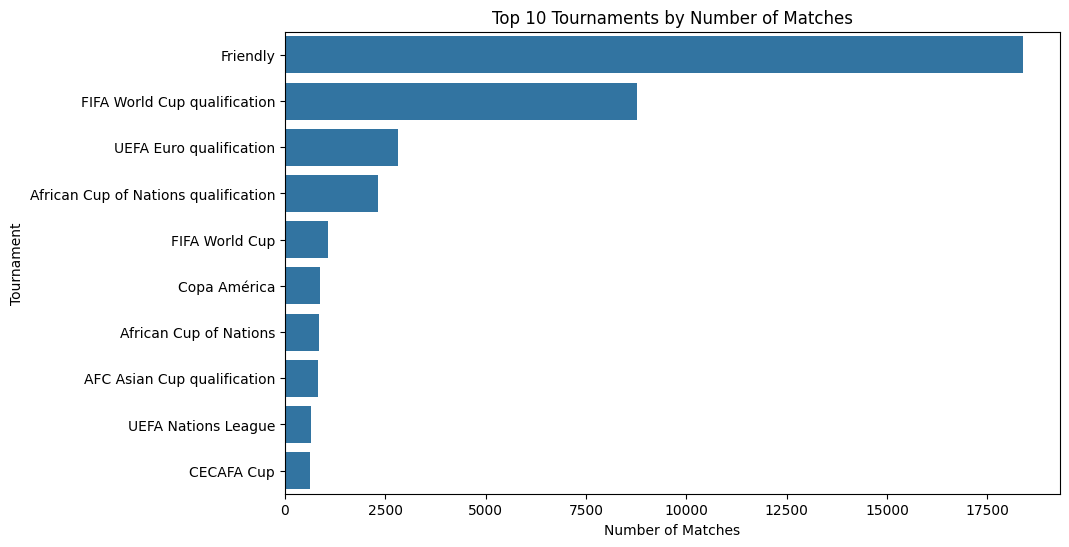

In [ ]:
tournament_counts = results["tournament"].value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=tournament_counts.values, y=tournament_counts.index)

plt.title("Top 10 Tournaments by Number of Matches")
plt.xlabel("Number of Matches")
plt.ylabel("Tournament")
plt.show()

#Goals per Match

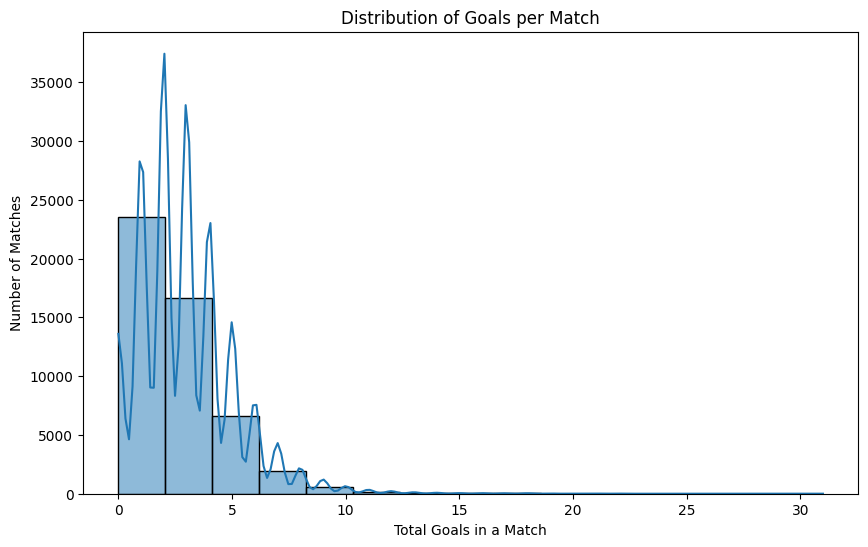

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(results["total_goals"], bins=15, kde=True)

plt.title("Distribution of Goals per Match")
plt.xlabel("Total Goals in a Match")
plt.ylabel("Number of Matches")
plt.show()

#Home vs Away Goals

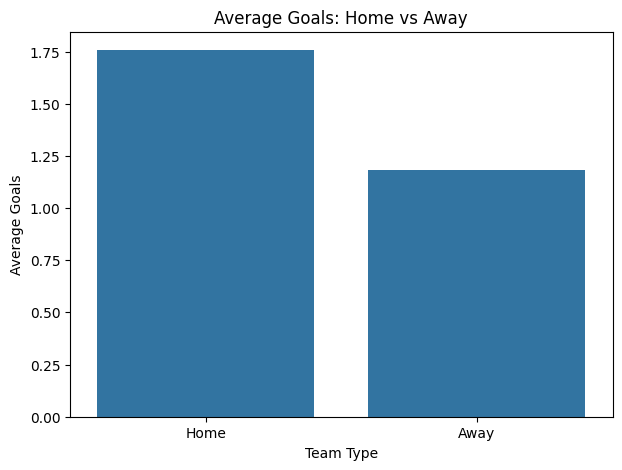

In [ ]:
goal_data = pd.DataFrame({
    "Team Type": ["Home", "Away"],
    "Average Goals": [
        results["home_score"].mean(),
        results["away_score"].mean()
    ]
})

plt.figure(figsize=(7, 5))
sns.barplot(data=goal_data, x="Team Type", y="Average Goals")

plt.title("Average Goals: Home vs Away")
plt.xlabel("Team Type")
plt.ylabel("Average Goals")
plt.show()

#Total Goals by Year

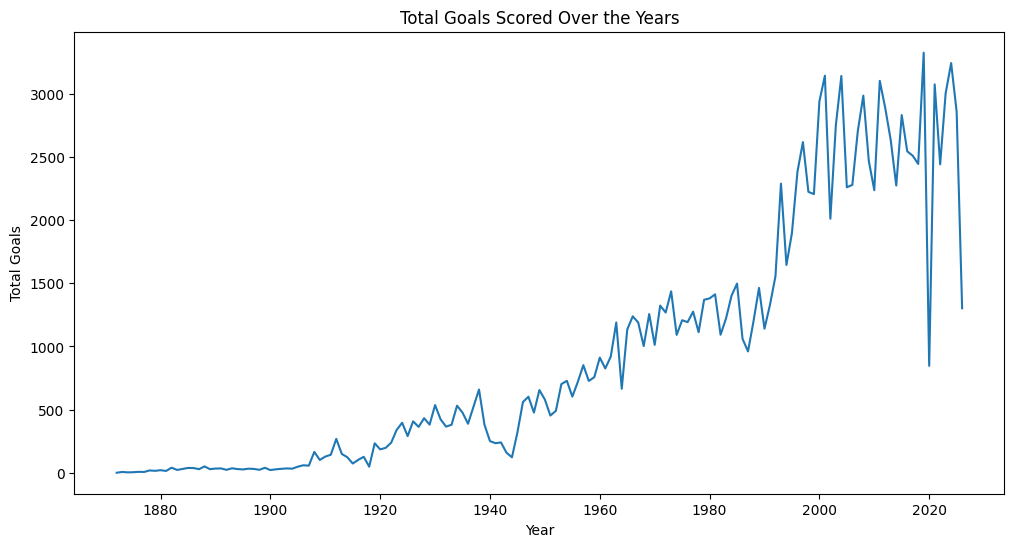

In [ ]:
yearly_goals = results.groupby("year")["total_goals"].sum()

plt.figure(figsize=(12, 6))
plt.plot(yearly_goals.index, yearly_goals.values)

plt.title("Total Goals Scored Over the Years")
plt.xlabel("Year")
plt.ylabel("Total Goals")
plt.show()

#Top 10 Goal Scorers

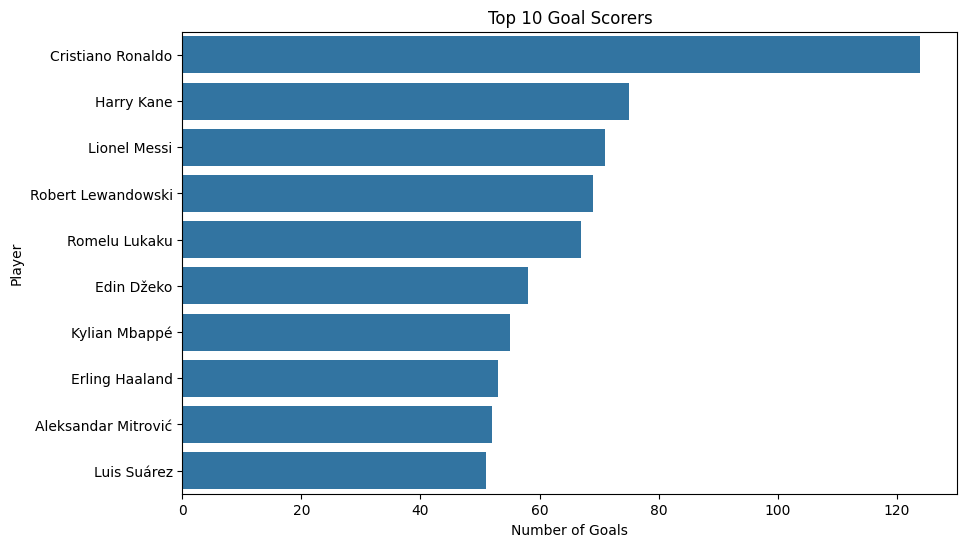

In [ ]:
top_scorers = goalscorers["scorer"].value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_scorers.values, y=top_scorers.index)

plt.title("Top 10 Goal Scorers")
plt.xlabel("Number of Goals")
plt.ylabel("Player")
plt.show()

#Shootout Analysis

In [ ]:
print("Total shootout records:", len(shootouts))

print("\nShootout winners:")
print(shootouts["winner"].value_counts().head(10))

Total shootout records: 683

Shootout winners:
winner
Egypt           16
South Korea     15
Argentina       15
Zambia          14
Thailand        13
South Africa    13
Senegal         11
Iraq            11
Ivory Coast     10
Nigeria         10
Name: count, dtype: int64


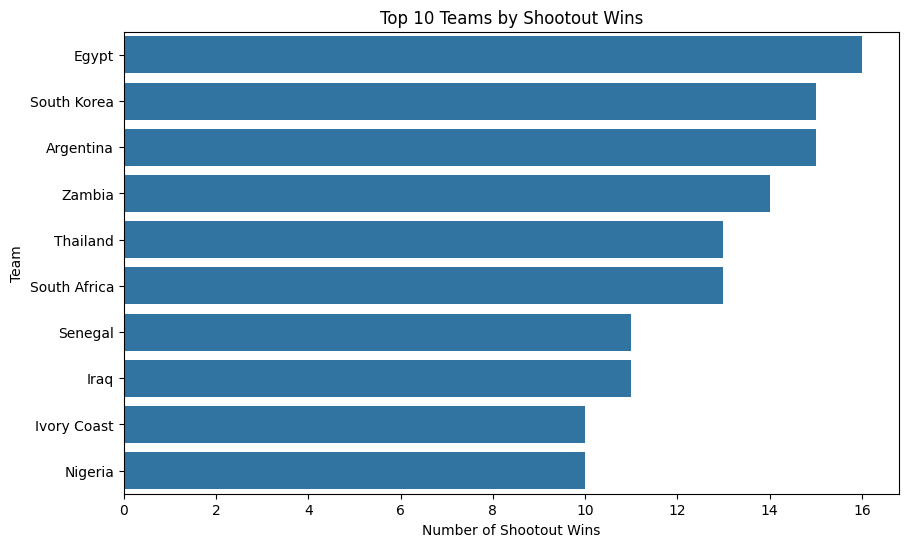

In [ ]:
shootout_winners = shootouts["winner"].value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=shootout_winners.values, y=shootout_winners.index)

plt.title("Top 10 Teams by Shootout Wins")
plt.xlabel("Number of Shootout Wins")
plt.ylabel("Team")
plt.show()

#Univariate & Bivariate Analysis

In [ ]:
player_counts = goalscorers["scorer"].value_counts().head(20)

print(player_counts)

scorer
Cristiano Ronaldo      124
Harry Kane              75
Lionel Messi            71
Robert Lewandowski      69
Romelu Lukaku           67
Edin Džeko              58
Kylian Mbappé           55
Erling Haaland          53
Aleksandar Mitrović     52
Luis Suárez             51
Ali Daei                49
Miroslav Klose          48
Carlos Ruiz             47
Zlatan Ibrahimović      44
Memphis Depay           44
Robbie Keane            44
David Villa             41
Clint Dempsey           41
Andriy Shevchenko       40
Samuel Eto'o            40
Name: count, dtype: int64


#Univariate & Bivariate Analysis

In [ ]:
player_counts = goalscorers["scorer"].value_counts().head(20)

print(player_counts)

scorer
Cristiano Ronaldo      124
Harry Kane              75
Lionel Messi            71
Robert Lewandowski      69
Romelu Lukaku           67
Edin Džeko              58
Kylian Mbappé           55
Erling Haaland          53
Aleksandar Mitrović     52
Luis Suárez             51
Ali Daei                49
Miroslav Klose          48
Carlos Ruiz             47
Zlatan Ibrahimović      44
Memphis Depay           44
Robbie Keane            44
David Villa             41
Clint Dempsey           41
Andriy Shevchenko       40
Samuel Eto'o            40
Name: count, dtype: int64


#Filter the Chosen Player

In [ ]:

player_name = "David Villa"

player_data = goalscorers[goalscorers["scorer"] == player_name].copy()

print("Player:", player_name)
print("Total goal records:", len(player_data))

display(player_data.head())

Player: David Villa
Total goal records: 41


,date,home_team,away_team,team,scorer,minute,own_goal,penalty,year
26005,2005-11-16,Slovakia,Spain,Spain,David Villa,71.0,False,False,2005
26118,2006-06-14,Spain,Ukraine,Spain,David Villa,17.0,False,False,2006
26119,2006-06-14,Spain,Ukraine,Spain,David Villa,48.0,False,True,2006
26213,2006-06-27,Spain,France,Spain,David Villa,28.0,False,True,2006
26299,2006-09-02,Spain,Liechtenstein,Spain,David Villa,45.0,False,False,2006


#career range

In [ ]:
print("First recorded year:", player_data["year"].min())
print("Last recorded year:", player_data["year"].max())

First recorded year: 2005
Last recorded year: 2014


In [ ]:
goals_by_year = player_data["year"].value_counts().sort_index()

print(goals_by_year)

year
2005    1
2006    6
2007    4
2008    9
2009    5
2010    7
2011    5
2013    3
2014    1
Name: count, dtype: int64


In [ ]:

print(player_counts)

scorer
Cristiano Ronaldo      124
Harry Kane              75
Lionel Messi            71
Robert Lewandowski      69
Romelu Lukaku           67
Edin Džeko              58
Kylian Mbappé           55
Erling Haaland          53
Aleksandar Mitrović     52
Luis Suárez             51
Ali Daei                49
Miroslav Klose          48
Carlos Ruiz             47
Zlatan Ibrahimović      44
Memphis Depay           44
Robbie Keane            44
David Villa             41
Clint Dempsey           41
Andriy Shevchenko       40
Samuel Eto'o            40
Name: count, dtype: int64


#Goals by Year

In [ ]:
goals_by_year = player_data.groupby("year").size()

print(goals_by_year)

year
2005    1
2006    6
2007    4
2008    9
2009    5
2010    7
2011    5
2013    3
2014    1
dtype: int64


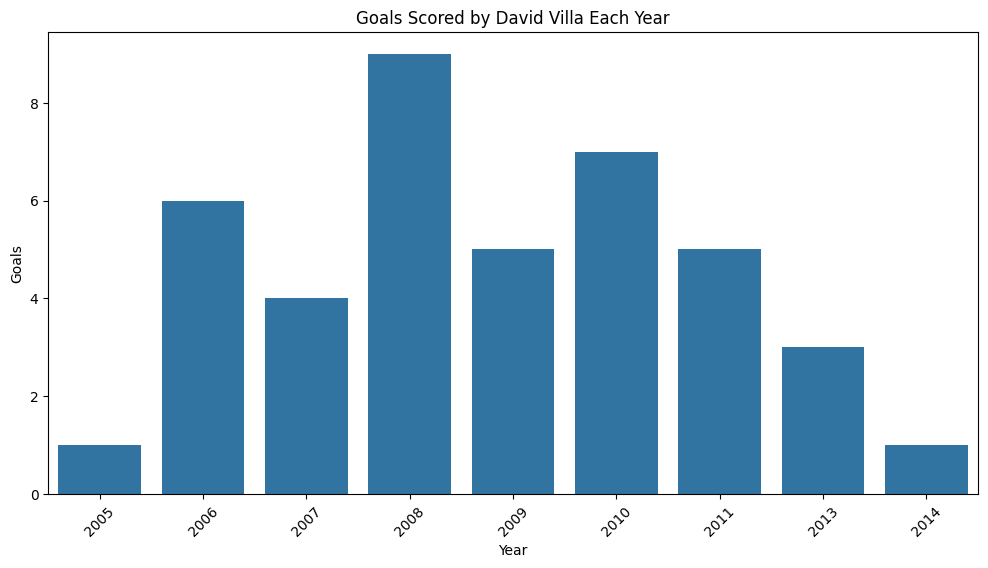

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=goals_by_year.index,
    y=goals_by_year.values
)

plt.title(f"Goals Scored by {player_name} Each Year")
plt.xlabel("Year")
plt.ylabel("Goals")

plt.xticks(rotation=45)
plt.show()

#Goal Minute

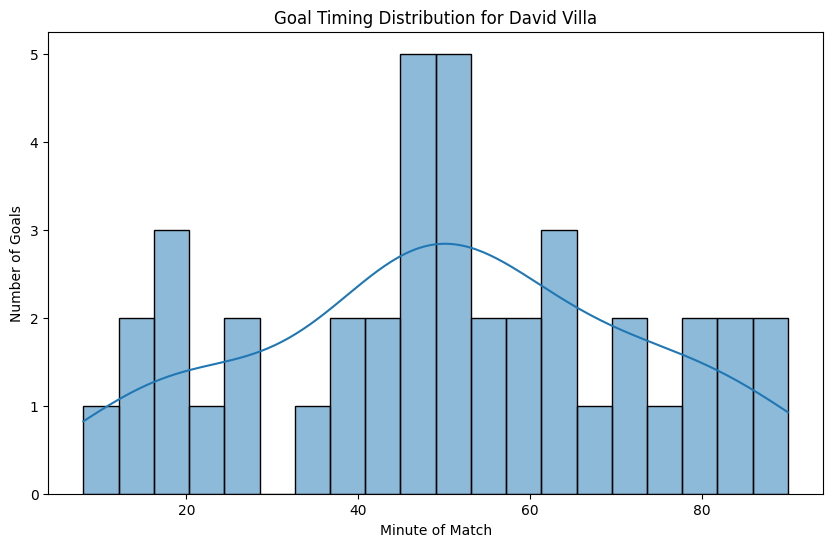

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    player_data["minute"].dropna(),
    bins=20,
    kde=True
)

plt.title(f"Goal Timing Distribution for {player_name}")
plt.xlabel("Minute of Match")
plt.ylabel("Number of Goals")

plt.show()

#Penalty Goals

In [ ]:
print(player_data["penalty"].value_counts(dropna=False))

penalty
False    37
True      4
Name: count, dtype: int64


In [ ]:
penalty_counts = player_data["penalty"].fillna(False).value_counts()

print(penalty_counts)

penalty
False    37
True      4
Name: count, dtype: int64


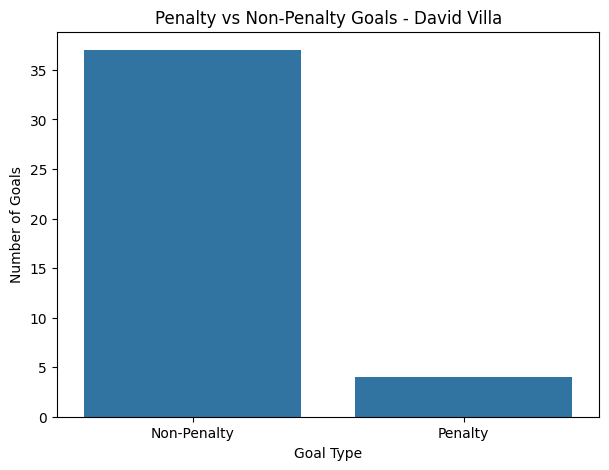

In [ ]:
labels = ["Non-Penalty", "Penalty"]

values = [
    penalty_counts.get(False, 0),
    penalty_counts.get(True, 0)
]

plt.figure(figsize=(7, 5))

sns.barplot(x=labels, y=values)

plt.title(f"Penalty vs Non-Penalty Goals - {player_name}")
plt.xlabel("Goal Type")
plt.ylabel("Number of Goals")

plt.show()

#Bivariate Analysis

In [ ]:
goals_by_year = (
    player_data.groupby("year")
    .size()
    .reset_index(name="goals")
)

display(goals_by_year)

,year,goals
0,2005,1
1,2006,6
2,2007,4
3,2008,9
4,2009,5
5,2010,7
6,2011,5
7,2013,3
8,2014,1


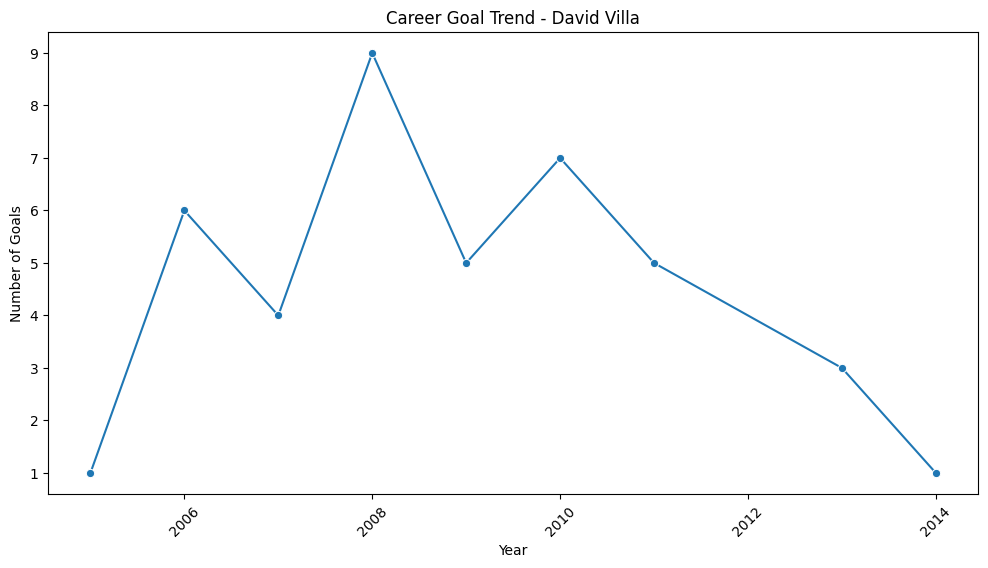

In [ ]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=goals_by_year,
    x="year",
    y="goals",
    marker="o"
)

plt.title(f"Career Goal Trend - {player_name}")
plt.xlabel("Year")
plt.ylabel("Number of Goals")
plt.xticks(rotation=45)

plt.show()

In [ ]:
best_year = goals_by_year.loc[goals_by_year["goals"].idxmax()]
lowest_year = goals_by_year.loc[goals_by_year["goals"].idxmin()]

print("Best recorded year:")
print(best_year)

print("\nLowest recorded year:")
print(lowest_year)

Best recorded year:
year     2008
goals       9
Name: 3, dtype: int64

Lowest recorded year:
year     2005
goals       1
Name: 0, dtype: int64


#Calculate penalty goals by year

In [ ]:
penalty_by_year = (
    player_data[player_data["penalty"] == True]
    .groupby("year")
    .size()
    .reset_index(name="penalty_goals")
)

display(penalty_by_year)

,year,penalty_goals
0,2006,2
1,2010,1
2,2011,1


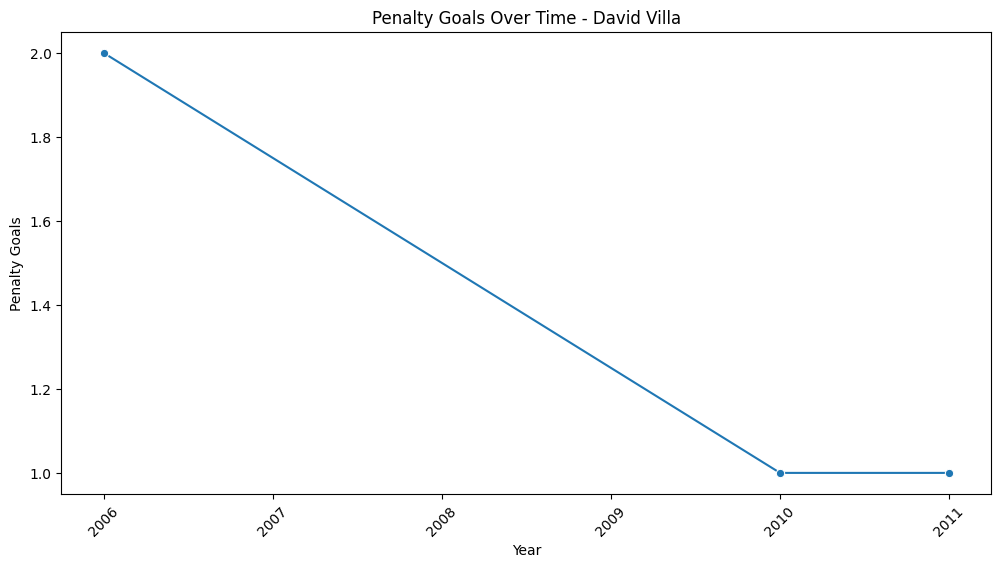

In [ ]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=penalty_by_year,
    x="year",
    y="penalty_goals",
    marker="o"
)

plt.title(f"Penalty Goals Over Time - {player_name}")
plt.xlabel("Year")
plt.ylabel("Penalty Goals")

plt.xticks(rotation=45)
plt.show()

In [ ]:
print(player_data["penalty"].unique())

[False  True]


#Calculate goals by tournament

In [ ]:
print(player_data.columns.tolist())

['date', 'home_team', 'away_team', 'team', 'scorer', 'minute', 'own_goal', 'penalty', 'year']


In [ ]:
player_data = player_data.merge(
    results[["date", "home_team", "away_team", "tournament"]],
    on=["date", "home_team", "away_team"],
    how="left"
)

display(player_data.head())

,date,home_team,away_team,team,scorer,minute,own_goal,penalty,year,tournament
0,2005-11-16,Slovakia,Spain,Spain,David Villa,71.0,False,False,2005,FIFA World Cup qualification
1,2006-06-14,Spain,Ukraine,Spain,David Villa,17.0,False,False,2006,FIFA World Cup
2,2006-06-14,Spain,Ukraine,Spain,David Villa,48.0,False,True,2006,FIFA World Cup
3,2006-06-27,Spain,France,Spain,David Villa,28.0,False,True,2006,FIFA World Cup
4,2006-09-02,Spain,Liechtenstein,Spain,David Villa,45.0,False,False,2006,UEFA Euro qualification


In [ ]:
print(player_data["tournament"].isna().sum())
print(player_data["tournament"].value_counts().head(10))

0
tournament
UEFA Euro qualification         14
FIFA World Cup                   9
FIFA World Cup qualification     8
Confederations Cup               6
UEFA Euro                        4
Name: count, dtype: int64


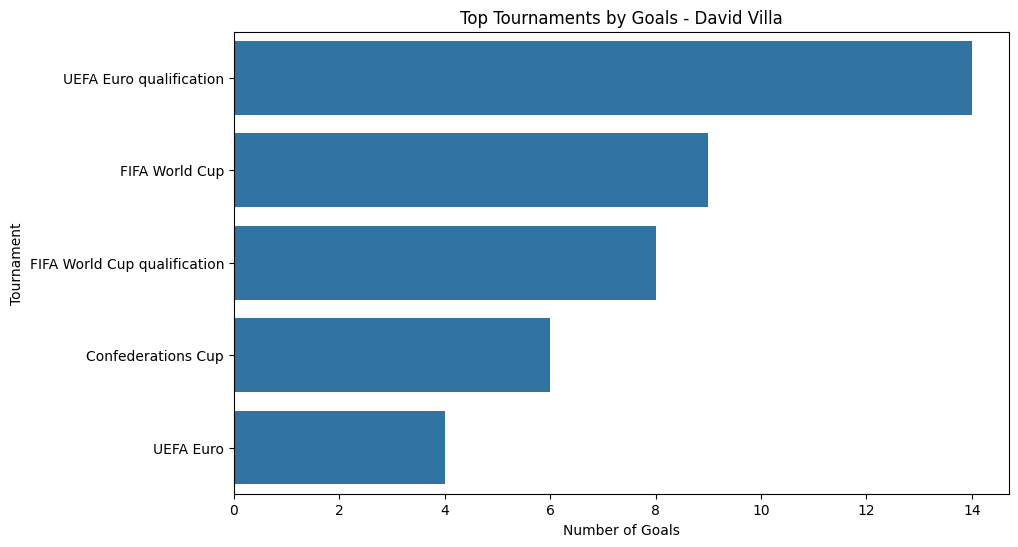

In [ ]:
goals_by_tournament = (
    player_data["tournament"]
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=goals_by_tournament.values,
    y=goals_by_tournament.index
)

plt.title(f"Top Tournaments by Goals - {player_name}")
plt.xlabel("Number of Goals")
plt.ylabel("Tournament")

plt.show()

#Count goals by team

In [ ]:
goals_by_team = (
    player_data["team"]
    .value_counts()
    .reset_index()
)

goals_by_team.columns = ["team", "goals"]

display(goals_by_team)

,team,goals
0,Spain,41


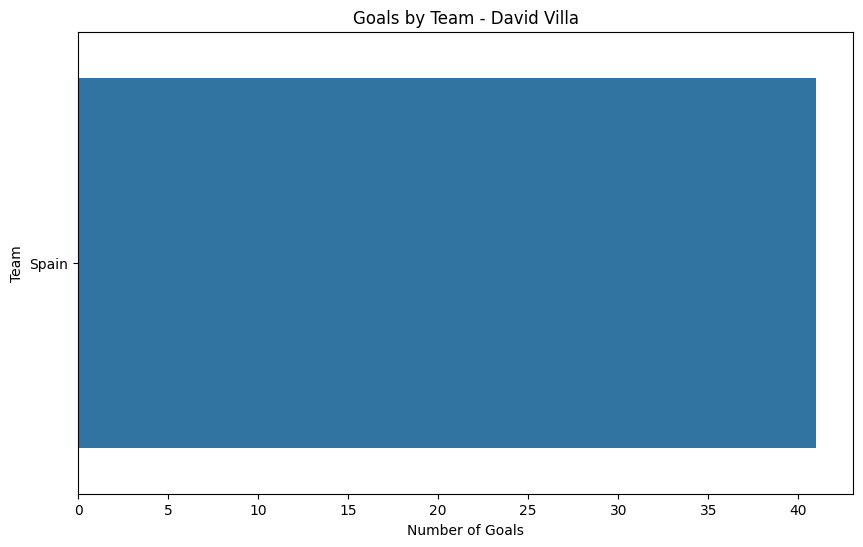

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=goals_by_team,
    x="goals",
    y="team"
)

plt.title(f"Goals by Team - {player_name}")
plt.xlabel("Number of Goals")
plt.ylabel("Team")

plt.show()

In [ ]:
print("Number of teams:", player_data["team"].nunique())

Number of teams: 1


#Univariate Analysis

In [ ]:
print(player_data["own_goal"].value_counts(dropna=False))

own_goal
False    41
Name: count, dtype: int64


In [ ]:
own_goal_counts = player_data["own_goal"].fillna(False).value_counts()

print(own_goal_counts)

own_goal
False    41
Name: count, dtype: int64


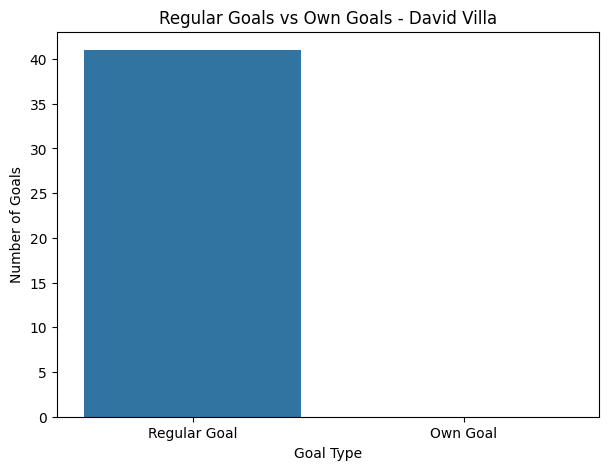

In [ ]:
labels = ["Regular Goal", "Own Goal"]

values = [
    own_goal_counts.get(False, 0),
    own_goal_counts.get(True, 0)
]

plt.figure(figsize=(7, 5))

sns.barplot(x=labels, y=values)

plt.title(f"Regular Goals vs Own Goals - {player_name}")
plt.xlabel("Goal Type")
plt.ylabel("Number of Goals")

plt.show()

In [ ]:
print("Player:", player_name)
print("Total recorded goal records:", len(player_data))
print("First recorded year:", player_data["year"].min())
print("Last recorded year:", player_data["year"].max())
print("Teams:", player_data["team"].nunique())
print("Tournaments:", player_data["tournament"].nunique())

Player: David Villa
Total recorded goal records: 41
First recorded year: 2005
Last recorded year: 2014
Teams: 1
Tournaments: 5


#Best and Worst Years

highest and lowest goal years

In [ ]:
best_year = goals_by_year.loc[goals_by_year["goals"].idxmax()]
worst_year = goals_by_year.loc[goals_by_year["goals"].idxmin()]

print("Best recorded year:")
print("Year:", int(best_year["year"]))
print("Goals:", int(best_year["goals"]))

print("\nLowest recorded year:")
print("Year:", int(worst_year["year"]))
print("Goals:", int(worst_year["goals"]))

Best recorded year:
Year: 2008
Goals: 9

Lowest recorded year:
Year: 2005
Goals: 1


best and worst years

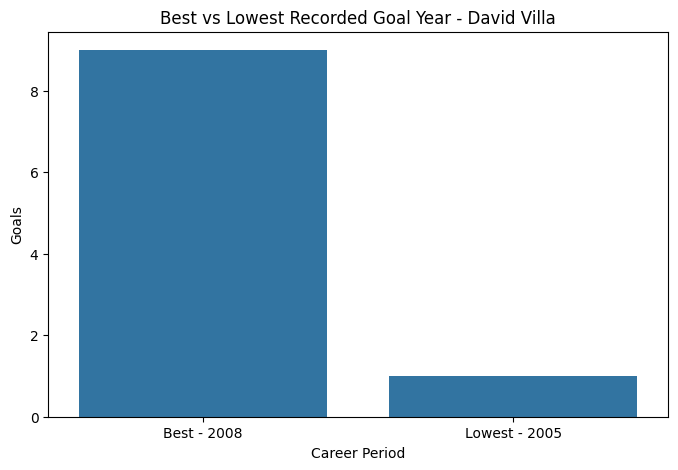

In [ ]:
best_worst = pd.DataFrame({
    "Period": [
        f"Best - {int(best_year['year'])}",
        f"Lowest - {int(worst_year['year'])}"
    ],
    "Goals": [
        int(best_year["goals"]),
        int(worst_year["goals"])
    ]
})

plt.figure(figsize=(8, 5))

sns.barplot(
    data=best_worst,
    x="Period",
    y="Goals"
)

plt.title(f"Best vs Lowest Recorded Goal Year - {player_name}")
plt.xlabel("Career Period")
plt.ylabel("Goals")

plt.show()

#Goals Over Time

In [ ]:
career_trend = (
    player_data.groupby("year")
    .size()
    .reset_index(name="goals")
    .sort_values("year")
)

display(career_trend)

,year,goals
0,2005,1
1,2006,6
2,2007,4
3,2008,9
4,2009,5
5,2010,7
6,2011,5
7,2013,3
8,2014,1


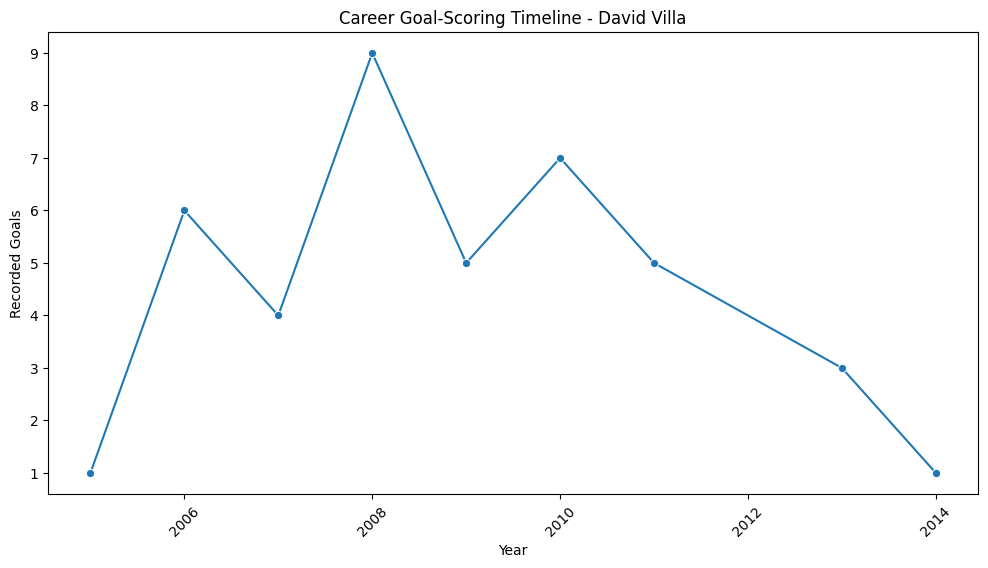

In [ ]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=career_trend,
    x="year",
    y="goals",
    marker="o"
)

plt.title(f"Career Goal-Scoring Timeline - {player_name}")
plt.xlabel("Year")
plt.ylabel("Recorded Goals")

plt.xticks(rotation=45)
plt.show()

In [ ]:
career_trend["goal_change"] = career_trend["goals"].diff()

display(career_trend)

,year,goals,goal_change
0,2005,1,NaN
1,2006,6,5.0
2,2007,4,-2.0
3,2008,9,5.0
4,2009,5,-4.0
5,2010,7,2.0
6,2011,5,-2.0
7,2013,3,-2.0
8,2014,1,-2.0


In [ ]:
biggest_increase = career_trend.loc[
    career_trend["goal_change"].idxmax()
]

print("Biggest increase:")
print(biggest_increase)

Biggest increase:
year           2006.0
goals             6.0
goal_change       5.0
Name: 1, dtype: float64


In [ ]:
biggest_decrease = career_trend.loc[
    career_trend["goal_change"].idxmin()
]

print("\nBiggest decrease:")
print(biggest_decrease)


Biggest decrease:
year           2009.0
goals             5.0
goal_change      -4.0
Name: 4, dtype: float64


In [ ]:
career_trend["goal_change"] = career_trend["goals"].diff()

biggest_increase = career_trend.loc[career_trend["goal_change"].idxmax()]
biggest_decrease = career_trend.loc[career_trend["goal_change"].idxmin()]

print("Biggest increase:")
print(biggest_increase)

print("\nBiggest decrease:")
print(biggest_decrease)

Biggest increase:
year           2006.0
goals             6.0
goal_change       5.0
Name: 1, dtype: float64

Biggest decrease:
year           2009.0
goals             5.0
goal_change      -4.0
Name: 4, dtype: float64
